# Setup

In [23]:
library(rtracklayer)
library(tidyverse)
library(DESeq2)
sessionInfo()

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘matrixStats’


The following object is masked from ‘package:dplyr’:

    count



Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, 

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] DESeq2_1.38.3               SummarizedExperiment_1.28.0
 [3] Biobase_2.58.0              MatrixGenerics_1.10.0      
 [5] matrixStats_1.4.1           lubridate_1.9.4            
 [7] forcats_1.0.0               stringr_1.5.1              
 [9] dplyr_1.1.4                 pur

In [3]:
BG   <- "/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/bedgraph"
metadata <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/4rep/gene_metadata.tsv"
ENSEMBL  <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/ENSEMBL/ensembl.canonical.prot-coding.transcript.tsv"
coldata <- 
OUT  <- "genebody_PROseq_counts.rds"

# generate counts matrix for differential expression

In [ ]:
# exclude TSS to mitigate effect of variable promoter proximal pausing. Calculate counts over TSS+250bp to TES
# only include sense-strand counts

In [6]:
#gene-level metadata, same genes as assayed for steady state RNAseq (n = 4 reps)
meta <- read.delim(metadata)
#ENSEMBL canonical transcript annotations
ens  <- read.delim(ENSEMBL)
ens  <- ens[match(meta$gene_id_base, ens$Gene.stable.ID), ]

#ENSEMBL canonical TSS
tss   <- ens$Transcription.start.site..TSS.
plus  <- ens$Strand == 1

# counting window - TSS + 250bp to TES
start <- ifelse(plus, tss + 250, ens$Transcript.start..bp.)
end   <- ifelse(plus, ens$Transcript.end..bp., tss - 250)
#exclude genes with length < 250bp
keep  <- !is.na(ens$Gene.stable.ID) & (end - start) > 0
str(ens)
# number kept after filtering for <250bp genes
sum(keep)

'data.frame':	12572 obs. of  9 variables:
 $ Gene.stable.ID                : chr  "ENSG00000188976" "ENSG00000187961" "ENSG00000188290" "ENSG00000187608" ...
 $ Transcript.stable.ID          : chr  "ENST00000327044" "ENST00000338591" "ENST00000304952" "ENST00000649529" ...
 $ Chromosome.scaffold.name      : chr  "1" "1" "1" "1" ...
 $ Transcript.start..bp.         : int  944203 960584 998964 1013497 1020120 1081823 1203508 1211340 1216931 1232237 ...
 $ Transcript.end..bp.           : int  959256 965719 1000097 1014540 1056116 1116089 1206592 1214153 1232001 1235041 ...
 $ Strand                        : int  -1 1 -1 1 1 -1 -1 -1 -1 1 ...
 $ Transcription.start.site..TSS.: int  959256 960584 1000097 1013497 1020120 1116089 1206592 1214153 1232001 1232237 ...
 $ Gene.name                     : chr  "NOC2L" "KLHL17" "HES4" "ISG15" ...
 $ Transcript.type               : chr  "protein_coding" "protein_coding" "protein_coding" "protein_coding" ...


[1] 12437

In [13]:
# make GRanges object with counting windows for each gene (excluding genes < 250bp in length)

genes <- GRanges(meta$chr[keep], IRanges(start[keep], end[keep]),
                 strand  = ifelse(plus[keep], "+", "-"),
                 gene_id = meta$gene_id_base[keep])
genes

GRanges object with 12437 ranges and 1 metadata column:
          seqnames              ranges strand |         gene_id
             <Rle>           <IRanges>  <Rle> |     <character>
      [1]     chr1       944203-959006      - | ENSG00000188976
      [2]     chr1       960834-965719      + | ENSG00000187961
      [3]     chr1       998964-999847      - | ENSG00000188290
      [4]     chr1     1013747-1014540      + | ENSG00000187608
      [5]     chr1     1020370-1056116      + | ENSG00000188157
      ...      ...                 ...    ... .             ...
  [12433]     chrX 155459415-155459755      - | ENSG00000277745
  [12434]     chrX 155489011-155612702      - | ENSG00000185973
  [12435]     chrX 155881595-155943769      + | ENSG00000124333
  [12436]     chrX 155997946-156010817      + | ENSG00000124334
  [12437]     chrX 156021211-156025374      + | ENSG00000182484
  -------
  seqinfo: 23 sequences from an unspecified genome; no seqlengths

In [19]:
#counting function
count_sense <- function(lib, sgn) {
    f   <- sprintf("%s/%s_hg38_dedup_3pr_%s.bedGraph", BG, lib,
                   if (sgn == "+") "forward" else "reverse") #construct path to bedgraph
    bg  <- import(f, format = "bedGraph") # read in bedgraph as GRanges obj
    g   <- genes[strand(genes) == sgn] # filter gene metadata GRanges to match strandedness of bedGraph
    ov  <- findOverlaps(g, bg, ignore.strand = TRUE) #map genes to overlapping bedgraph positions
    v   <- tapply(bg$score[subjectHits(ov)], queryHits(ov), sum) # sum bedGraph signal over window
    out <- setNames(numeric(length(g)), g$gene_id)
    out[as.integer(names(v))] <- v
    out
}

In [21]:
#clean up sample names - only include condition, rep, and unique identifier
libs   <- sub("_hg38_dedup_3pr_forward[.]bedGraph$", "",
              basename(Sys.glob(file.path(BG, "*_3pr_forward.bedGraph"))))
counts <- sapply(libs, function(l)
              c(count_sense(l, "+"), count_sense(l, "-"))[genes$gene_id]) # for each bedgraph, generate counts per-gene (only consider genes matching strand of bedGraph)
colnames(counts) <- sub("^Gorkin001_PR_[0-9]+_", "", libs) #make colnames condition + replicate



In [204]:
write.table(counts, "PRO_counts_genes.tsv", sep='\t', row.names=F, quote=F)
write.table(data.frame(genes), "PRO_genes_metadata.tsv", sep='\t', row.names=F, quote=F)


# run differential expression

In [54]:
coldata <- data.frame(sample=colnames(counts), 
                 condition=sub("_.$","",colnames(counts)),
                 rep=sub("^.*_","",colnames(counts)))

dds <- DESeqDataSetFromMatrix(countData=counts, colData=coldata, design=~condition)
des <- DESeq(dds)

deg_res <- function (des, row.data, contrast) 
{
    res <- results(des, contrast = contrast)
    res <- res %>% data.frame() %>% rownames_to_column("ENSEMBL_ID") %>% 
            mutate(gene=row.data$gene_name,change = case_when(log2FoldChange > log2(1.5) & 
                                      padj < 0.05 ~ "up", 
                                      log2FoldChange < -log2(1.5) & padj < 0.05 ~ "down", 
                                      TRUE ~ "ns"))
    return(res)
}

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [143]:
ifn_v_veh <- deg_res(des, meta[keep,], c("condition", "veh_IFN", "veh_veh"))
brm_v_veh <- deg_res(des, meta[keep,], c("condition", "BAFinh_veh", "veh_veh"))
brm_ifn_v_ifn <- deg_res(des, meta[keep,], c("condition", "BAFinh_IFN", "veh_IFN"))

write.table(ifn_v_veh, "PRO_DEGs_IFN_Veh.tsv", sep='\t', row.names=F)
write.table(brm_v_veh, "PRO_DEGs_BAFinh_Veh.tsv", sep='\t', row.names=F)
write.table(brm_ifn_v_ifn, "PRO_DEGs_BAFinh_IFN_IFN.tsv", sep='\t', row.names=F)

# PCA

Coordinate system already present. Adding new coordinate system, which will
replace the existing one.


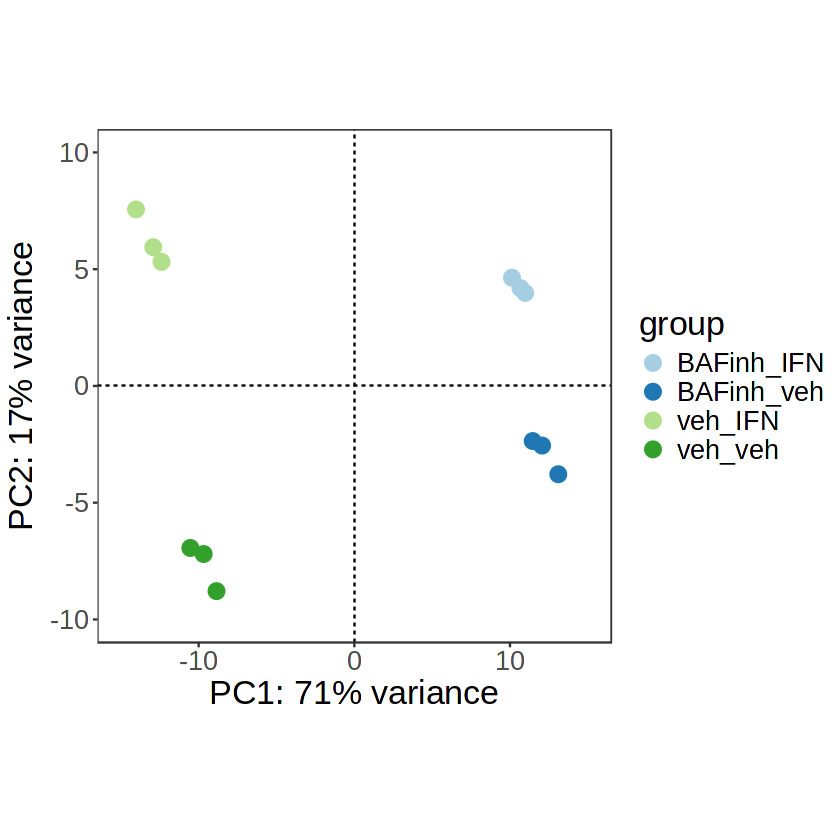

In [177]:
saveRDS(dds, "PROseq_gene_dds.rds")
plotPCA(rlog(dds), ntop=12437) + 
    geom_point(size=4) + 
    geom_vline(xintercept=0,linetype=2) + geom_hline(yintercept=0, linetype=2) +
    scale_color_brewer(palette="Paired") + theme_bw() +
    xlim(-15,15) + ylim(-10,10) + coord_fixed(ratio=30/20) + theme(text=element_text(size=20), panel.grid=element_blank())